In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

In [5]:
# Set reproducible seeds
np.random.seed(42)
tf.random.set_seed(42)

In [6]:
# ==============================================================================
# 1. SYNTHETIC DATA GENERATION: RELATIONAL & ORGANIZATIONAL DYSFUNCTION MODEL
# ==============================================================================
# Models how mental health strain & toxic relational patterns (familial, romantic,
# professional, one-sided, codependent) propagate into governance failures and
# financial/stock deterioration across 2,500 company-quarters.

n_samples = 2500

# Input Features (0 to 10 severity / prevalence scales)
mental_health_strain = np.random.uniform(1.0, 10.0, n_samples)          # Unresolved stress, burnout, emotional dysregulation
familial_enmeshment_nepotism = np.clip(
    0.45 * mental_health_strain + np.random.normal(1.5, 1.4, n_samples), 0, 10
)                                                                       # Family-style favoritism, scapegoating, nepotistic hiring
workplace_romantic_favoritism = np.clip(
    0.40 * mental_health_strain + np.random.normal(1.2, 1.5, n_samples), 0, 10
)                                                                       # Unchecked workplace romantic & codependent power dynamics
toxic_leadership_index = np.clip(
    0.50 * mental_health_strain
    + 0.25 * familial_enmeshment_nepotism
    + 0.25 * workplace_romantic_favoritism
    + np.random.normal(0, 0.9, n_samples),
    0, 10
)                                                                       # One-sided blame-shifting, gaslighting, retaliatory culture

# Intermediate Organizational Governance Failures
hiring_fraud_index = np.clip(
    0.42 * familial_enmeshment_nepotism
    + 0.38 * workplace_romantic_favoritism
    + 0.20 * toxic_leadership_index
    + np.random.normal(0, 0.8, n_samples),
    0, 10
)                                                                       # Credentials falsification, unqualified friends/relatives hired

good_employee_layoff_rate = np.clip(
    3.0
    + 2.4 * toxic_leadership_index
    + 1.8 * hiring_fraud_index
    + np.random.normal(0, 2.0, n_samples),
    1.0, 45.0
)                                                                       # % of top-quartile performers pushed out or laid off unfairly

colleague_risk_index = np.clip(
    0.45 * toxic_leadership_index
    + 0.35 * mental_health_strain
    + 0.20 * hiring_fraud_index
    + np.random.normal(0, 0.7, n_samples),
    0, 10
)                                                                       # Psychological & operational safety risk to remaining staff

# Target Outputs: Company Performance & Stock Valuation Impact
company_performance_score = np.clip(
    92.0
    - 3.4 * toxic_leadership_index
    - 2.1 * hiring_fraud_index
    - 0.65 * good_employee_layoff_rate
    - 1.5 * colleague_risk_index
    + np.random.normal(0, 2.5, n_samples),
    10.0, 100.0
)                                                                       # Operational KPI, innovation & productivity index (0-100)

stock_price_change_pct = np.clip(
    14.0
    + 0.45 * (company_performance_score - 65.0)
    - 1.6 * hiring_fraud_index
    - 0.55 * good_employee_layoff_rate
    - 1.2 * colleague_risk_index
    + np.random.normal(0, 3.2, n_samples),
    -55.0, 35.0
)                                                                       # Quarterly stock return (%)

df = pd.DataFrame({
    "Mental_Health_Strain": mental_health_strain,
    "Familial_Nepotism": familial_enmeshment_nepotism,
    "Workplace_Romance_Bias": workplace_romantic_favoritism,
    "Toxic_Leadership": toxic_leadership_index,
    "Hiring_Fraud_Index": hiring_fraud_index,
    "Good_Employee_Layoff_Pct": good_employee_layoff_rate,
    "Colleague_Risk_Index": colleague_risk_index,
    "Company_Performance": company_performance_score,
    "Stock_Return_Pct": stock_price_change_pct
})

print("Dataset Preview:")
print(df.head().round(2))

Dataset Preview:
   Mental_Health_Strain  Familial_Nepotism  Workplace_Romance_Bias  \
0                  4.37               4.20                    4.21   
1                  9.56               6.70                    6.77   
2                  7.59               5.69                    3.37   
3                  6.39               4.50                    2.02   
4                  2.40               2.31                    3.44   

   Toxic_Leadership  Hiring_Fraud_Index  Good_Employee_Layoff_Pct  \
0              4.74                4.23                     19.58   
1              7.84                7.16                     32.72   
2              6.23                5.35                     25.93   
3              5.31                2.72                     20.73   
4              2.12                3.84                     15.16   

   Colleague_Risk_Index  Company_Performance  Stock_Return_Pct  
0                  4.61                43.08            -17.51  
1                

In [7]:
# ==============================================================================
# 2. PREPROCESSING & TENSORFLOW / KERAS MULTI-OUTPUT NEURAL NETWORK
# ==============================================================================
feature_cols = [
    "Mental_Health_Strain",
    "Familial_Nepotism",
    "Workplace_Romance_Bias",
    "Toxic_Leadership",
    "Hiring_Fraud_Index",
    "Good_Employee_Layoff_Pct",
    "Colleague_Risk_Index"
]
target_cols = ["Company_Performance", "Stock_Return_Pct"]

X = df[feature_cols].values
y = df[target_cols].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Build Functional Keras Neural Network with Dual Regression Heads
inputs = keras.Input(shape=(len(feature_cols),), name="relational_risk_inputs")
x = layers.Dense(64, activation="relu")(inputs)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.15)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)

# Output 1: Company Operational Performance (0-100)
perf_output = layers.Dense(1, name="company_performance")(x)
# Output 2: Quarterly Stock Price Change (%)
stock_output = layers.Dense(1, name="stock_return")(x)

model = keras.Model(
    inputs=inputs,
    outputs=[perf_output, stock_output],
    name="Toxic_Relationship_Impact_DNN"
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss={
        "company_performance": "mse",
        "stock_return": "mse"
    },
    metrics={
        "company_performance": ["mae"],
        "stock_return": ["mae"]
    }
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    {"company_performance": y_train[:, 0], "stock_return": y_train[:, 1]},
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

# Model Evaluation
pred_perf, pred_stock = model.predict(X_test_scaled, verbose=0)
pred_perf = pred_perf.flatten()
pred_stock = pred_stock.flatten()

print("\n--- Neural Network Test Set Performance ---")
print(f"Company Performance -> R²: {r2_score(y_test[:, 0], pred_perf):.3f} | MAE: {mean_absolute_error(y_test[:, 0], pred_perf):.2f} pts")
print(f"Stock Return (%)    -> R²: {r2_score(y_test[:, 1], pred_stock):.3f} | MAE: {mean_absolute_error(y_test[:, 1], pred_stock):.2f}%")


--- Neural Network Test Set Performance ---
Company Performance -> R²: 0.972 | MAE: 2.46 pts
Stock Return (%)    -> R²: 0.948 | MAE: 3.31%


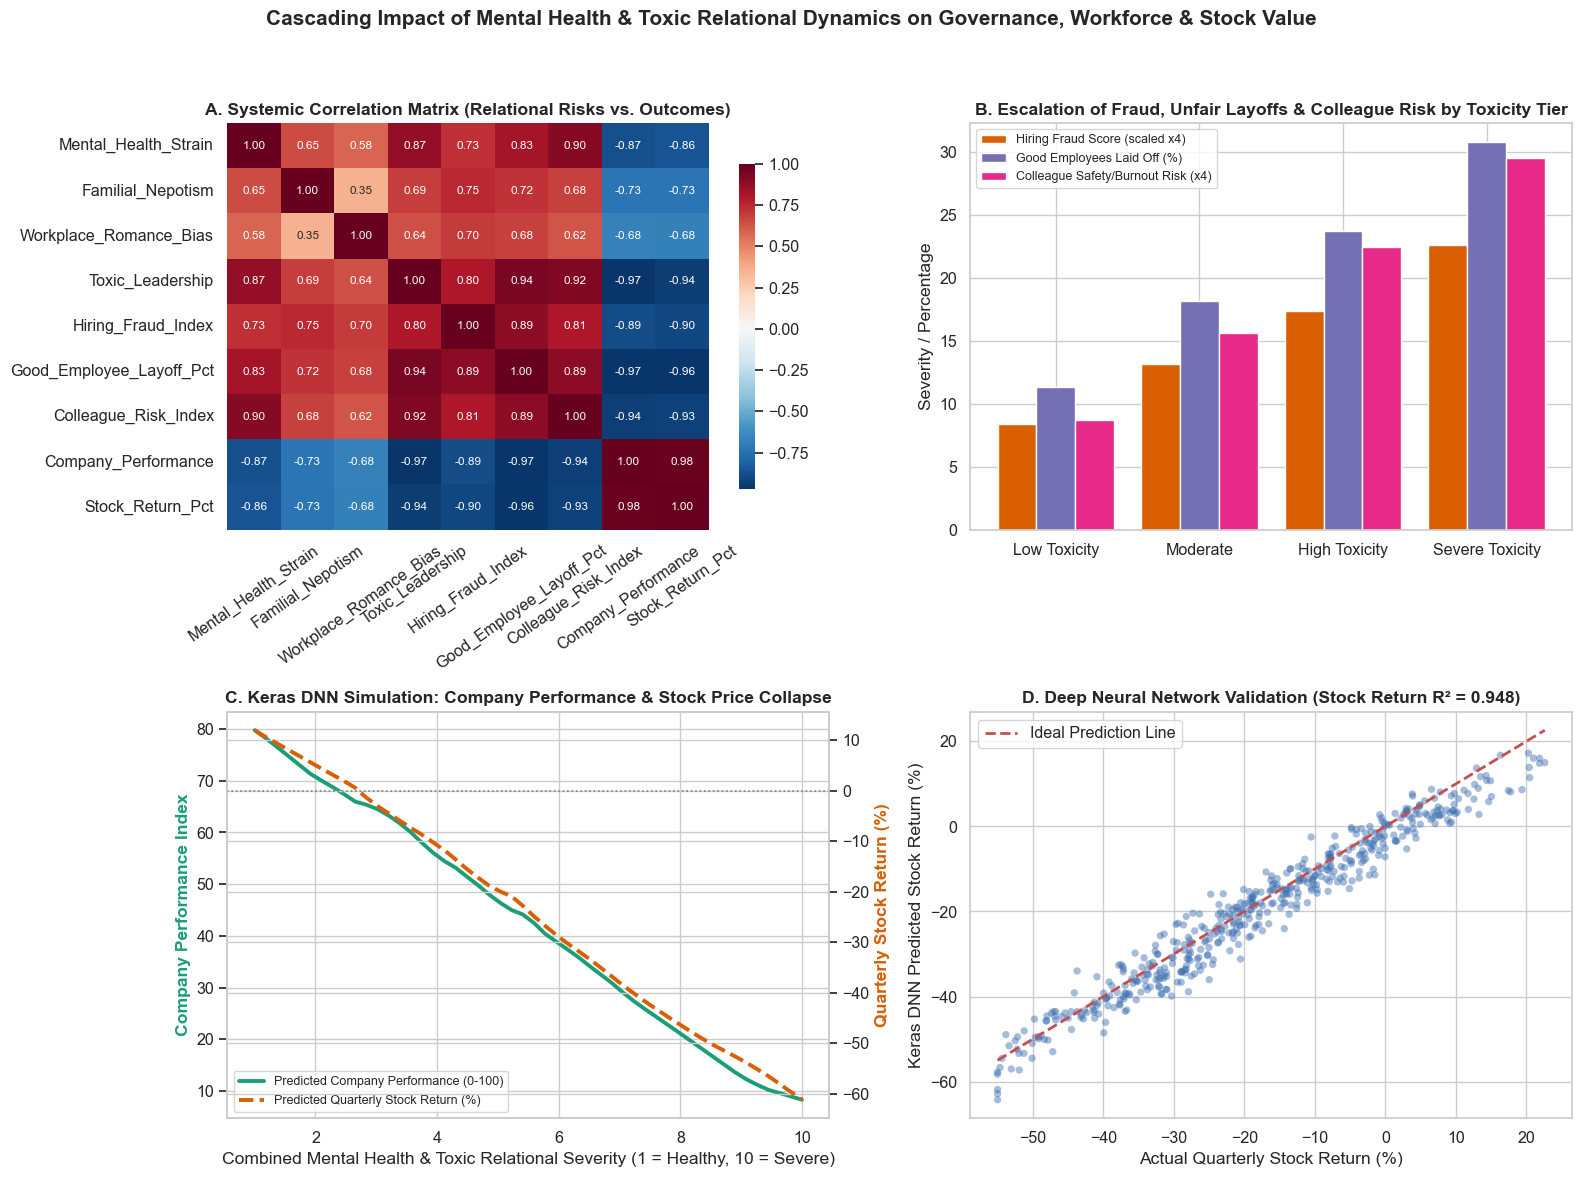

In [8]:
# ==============================================================================
# 3. VISUALIZATION DASHBOARD (4 ANALYTICAL GRAPHS)
# ==============================================================================
sns.set_theme(style="whitegrid", font_scale=1.05)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Cascading Impact of Mental Health & Toxic Relational Dynamics on Governance, Workforce & Stock Value",
    fontsize=15, fontweight="bold", y=0.98
)

# Panel A: Correlation Heatmap across Mental Health, Family/Romantic Bias, Fraud & Stock
corr_matrix = df.corr()
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    ax=axes[0, 0], cbar_kws={"shrink": 0.8}, annot_kws={"size": 8.5}
)
axes[0, 0].set_title("A. Systemic Correlation Matrix (Relational Risks vs. Outcomes)", fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=35)

# Panel B: Nepotism & Workplace Romance Driving Hiring Fraud & Good Employee Layoffs
df["Toxicity_Tier"] = pd.qcut(
    df["Toxic_Leadership"], q=4,
    labels=["Low Toxicity", "Moderate", "High Toxicity", "Severe Toxicity"]
)
tier_summary = df.groupby("Toxicity_Tier", observed=False)[[
    "Hiring_Fraud_Index", "Good_Employee_Layoff_Pct", "Colleague_Risk_Index"
]].mean().reset_index()

x_pos = np.arange(len(tier_summary))
width = 0.27
axes[0, 1].bar(x_pos - width, tier_summary["Hiring_Fraud_Index"] * 4, width, label="Hiring Fraud Score (scaled x4)", color="#d95f02")
axes[0, 1].bar(x_pos, tier_summary["Good_Employee_Layoff_Pct"], width, label="Good Employees Laid Off (%)", color="#7570b3")
axes[0, 1].bar(x_pos + width, tier_summary["Colleague_Risk_Index"] * 4, width, label="Colleague Safety/Burnout Risk (x4)", color="#e7298a")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(tier_summary["Toxicity_Tier"])
axes[0, 1].set_ylabel("Severity / Percentage")
axes[0, 1].set_title("B. Escalation of Fraud, Unfair Layoffs & Colleague Risk by Toxicity Tier", fontweight="bold")
axes[0, 1].legend(frameon=True, fontsize=9)

# Panel C: Neural Network Stress-Test Simulation (Stock Trajectory as Dysfunction Escalates)
sim_steps = np.linspace(1, 10, 50)
sim_df = pd.DataFrame({
    "Mental_Health_Strain": sim_steps,
    "Familial_Nepotism": 0.85 * sim_steps,
    "Workplace_Romance_Bias": 0.80 * sim_steps,
    "Toxic_Leadership": 0.90 * sim_steps,
    "Hiring_Fraud_Index": 0.85 * sim_steps,
    "Good_Employee_Layoff_Pct": 3.0 + 3.8 * sim_steps,
    "Colleague_Risk_Index": 0.88 * sim_steps
})
sim_scaled = scaler_X.transform(sim_df.values)
sim_perf, sim_stock = model.predict(sim_scaled, verbose=0)

ax_c = axes[1, 0]
ax_c_twin = ax_c.twinx()
l1 = ax_c.plot(sim_steps, sim_perf.flatten(), color="#1b9e77", linewidth=2.8, label="Predicted Company Performance (0-100)")
l2 = ax_c_twin.plot(sim_steps, sim_stock.flatten(), color="#d95f02", linewidth=2.8, linestyle="--", label="Predicted Quarterly Stock Return (%)")
ax_c_twin.axhline(0, color="gray", linestyle=":", linewidth=1.2)
ax_c.set_xlabel("Combined Mental Health & Toxic Relational Severity (1 = Healthy, 10 = Severe)")
ax_c.set_ylabel("Company Performance Index", color="#1b9e77", fontweight="bold")
ax_c_twin.set_ylabel("Quarterly Stock Return (%)", color="#d95f02", fontweight="bold")
ax_c.set_title("C. Keras DNN Simulation: Company Performance & Stock Price Collapse", fontweight="bold")
lines = l1 + l2
labels = [l.get_label() for l in lines]
ax_c.legend(lines, labels, loc="lower left", fontsize=9)

# Panel D: Neural Network Actual vs. Predicted Stock Return (%)
axes[1, 1].scatter(y_test[:, 1], pred_stock, alpha=0.45, color="#386cb0", edgecolors="none", s=28)
min_val, max_val = y_test[:, 1].min(), y_test[:, 1].max()
axes[1, 1].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Ideal Prediction Line")
axes[1, 1].set_xlabel("Actual Quarterly Stock Return (%)")
axes[1, 1].set_ylabel("Keras DNN Predicted Stock Return (%)")
axes[1, 1].set_title(f"D. Deep Neural Network Validation (Stock Return R² = {r2_score(y_test[:, 1], pred_stock):.3f})", fontweight="bold")
axes[1, 1].legend(loc="upper left")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("toxic_workplace_stock_impact_dashboard.png", dpi=300)
plt.show()